# Этап 08. Эволюция экономических кластеров муниципалитетов

## 1. Цель и связь с предыдущими этапами

**Цель** — исследовать, как изменяются экономические группы 2016 муниципалитетов в 24 месячных срезах (2023–2024), отличая перестановку номеров сообществ от реальной смены состава.

- **Шаг 05:** месячные CLR-признаки, 6 категорий расходов.
- **Шаг 06:** 24 графа экономического сходства, CLR + union kNN, $k=10$.
- **Шаг 07:** независимые месячные разбиения K-Means, Leiden и Spectral. Для основного временного сравнения используем **K-Means**, предварительного кандидата этапа 07. Графы нужны для оценки и графовой поддержки временной модели.

Проводим **ретроспективный** анализ, а не прогноз: сопоставление кластеров и временная регуляризация могут использовать состав сообществ всех рассматриваемых месяцев. При построении месячных признаков и графов будущие месяцы не используются. Годовые изменения БДМО изучаются только после получения разбиений, как независимая объясняющая информация.

## 2. Математическая постановка: сопоставление сообществ

Пусть $g_i^{(0)}(t)$ — независимая метка муниципалитета $i$ в месяце $t$. Её числовое значение не сопоставимо между месяцами. Для двух соседних разбиений определяем пересечение:

$$
M_{ab}(t)=\left|\{i:g_i(t)=a,\;g_i^{(0)}(t+1)=b\}\right|.
$$

Основное взаимно однозначное соответствие находим **алгоритмом Hungarian**, максимизируя $\sum_{(a,b)\in\mathcal{A}_t}M_{ab}(t)$ по частичному паросочетанию $\mathcal{A}_t$. Сохраняем старый сквозной ID, только если пересечение положительно и удовлетворяет заданному порогу Жаккара; иначе создаём новый ID.

**Разделения и слияния** определяем отдельно по всей таблице потоков, включая связи, не выбранные Hungarian. Разделение: у исходного сообщества несколько существенных получателей; слияние: несколько существенных источников у одного получателя. Это **операционные сигналы** на основе размеров пересечений, а не доказательство причин реорганизации.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.feature_analysis import parse_dynamic_columns
from src.cluster_models import read_graph_sequence
from src.temporal_analysis import (
    validate_inputs, raw_labels, align_history, transitions, time_metrics,
    features_by_month, attribute_change_association, run_lambda_grid,
    delta_transition_associations, plot_flow_three_periods, save_results,
)

cfg = json.loads((ROOT / 'configs' / 'clustering_experiment.json').read_text(encoding='utf-8'))
tcfg = cfg['temporal_08']
X_dynamic = pd.read_parquet(ROOT / cfg['feature_path'])
labels07 = pd.read_parquet(ROOT / cfg['output_directory'] / 'labels.parquet')
mapping = parse_dynamic_columns(X_dynamic)
months = [str(m) for m in sorted({m for m, _ in mapping})]
graphs = read_graph_sequence(ROOT / cfg['graph_directory'], X_dynamic.index, months)
method = tcfg['base_method']
validate_inputs(X_dynamic.index, labels07, graphs, months, method)

print('Муниципалитеты:', len(X_dynamic), '| Месяцы:', len(months),
      '| Метод:', method, '| Интервал:', months[0], '—', months[-1])
print('Форма меток этапа 07:', labels07.shape, '| Графов:', len(graphs))

Муниципалитеты: 2016 | Месяцы: 24 | Метод: kmeans | Интервал: 2023-01 — 2024-12
Форма меток этапа 07: (2016, 72) | Графов: 24


## 3. Независимые разбиения и сквозные идентификаторы

На основе сохранённых меток этапа 07 выстраиваем сквозные идентификаторы по месячным пересечениям. Проверяем сохранение муниципального индекса и отсутствие искусственных переходов из-за произвольной перестановки номеров. Для анализа разделений/слияний применяем минимальный размер потока и относительный порог, указанные в конфигурации.

In [2]:
original = raw_labels(labels07, months, method)
independent, events = align_history(
    original,
    min_jaccard=tcfg['matching_min_jaccard'],
    event_fraction=tcfg['event_min_fraction'],
    min_event_size=tcfg['event_min_size'],
)
assert independent.index.equals(X_dynamic.index)
assert independent.shape == (len(X_dynamic),24)
print('Сквозных идентификаторов:', len(pd.unique(independent.to_numpy().ravel())))
print('Зафиксированные события разделения / слияния:')
display(events.groupby('event').size().rename('events').to_frame() if not events.empty
        else pd.DataFrame({'events':[0]}, index=['нет сигналов']))
if not events.empty:
    display(events.head(8))

Сквозных идентификаторов: 4
Зафиксированные события разделения / слияния:


,events
event,
merge,20
split,21


,month_from,month_to,event,cluster,branches
0,2023-03,2023-04,split,3,2
1,2023-03,2023-04,merge,0,2
2,2023-07,2023-08,split,0,2
3,2023-07,2023-08,merge,2,2
4,2023-08,2023-09,split,0,2
5,2023-08,2023-09,merge,2,2
6,2023-09,2023-10,split,2,2
7,2023-09,2023-10,merge,0,2


## 4. Матрицы переходов и показатели временной устойчивости

Для согласованных меток строим численности $n_{ab}(t)$ и строково-нормированные вероятности перехода:

$$
P_{ab}(t)=\frac{\left|\{i:g_i(t)=a,\;g_i(t+1)=b\}\right|}{\left|\{i:g_i(t)=a\}\right|}.
$$

$P_{ab}(t)$ — **доля** муниципалитетов из типа $a$, попавшая в тип $b$ в следующий месяц; это не предсказанная вероятность отдельного муниципалитета. Для каждого источника $\sum_bP_{ab}(t)=1$.

Считаем долю сохранения метки, долю переходов, ARI и NMI соседних разбиений. В отличие от доли сохранения, ARI и NMI не зависят от названий кластеров. «Устойчивое сообщество» — один и тот же сквозной ID с Жаккаром составов не ниже порога из конфига.

Временная устойчивость (независимая кластеризация):


,stay_share,switch_share,ari,nmi,stable_communities
mean,0.891,0.109,0.742,0.733,3.913
50%,0.906,0.094,0.760,0.747,4.000
min,0.676,0.067,0.449,0.551,2.000
max,0.933,0.324,0.820,0.779,4.000


Крупнейшие межкластерные потоки (без сохранения собственного типа):


,month_from,month_to,source,target,count,probability
147,2023-10,2023-11,0,3,285,0.373
152,2023-10,2023-11,2,0,182,0.324
151,2023-10,2023-11,1,3,153,0.260
179,2023-12,2024-01,0,3,123,0.190
204,2024-01,2024-02,3,0,118,0.204
184,2023-12,2024-01,2,0,115,0.337
360,2024-11,2024-12,2,0,103,0.262
136,2023-09,2023-10,2,0,93,0.148


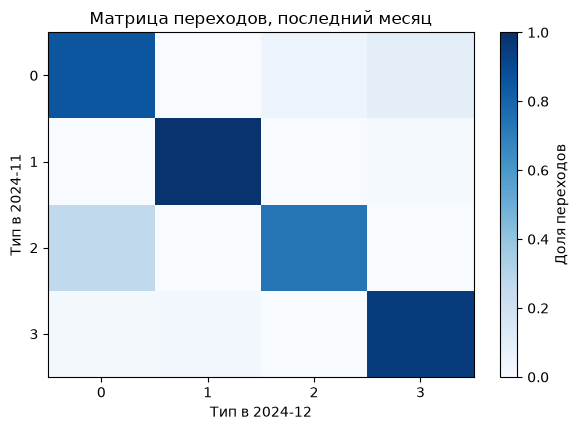

In [3]:
flows = transitions(independent)
stability = time_metrics(independent, tcfg['stable_cluster_jaccard'])
assert len(stability) == 23
assert np.allclose(flows.groupby(['month_from','source']).probability.sum().to_numpy(), 1)
print('Временная устойчивость (независимая кластеризация):')
display(stability[['stay_share','switch_share','ari','nmi','stable_communities']]
        .describe().loc[['mean','50%','min','max']].round(3))
print('Крупнейшие межкластерные потоки (без сохранения собственного типа):')
display(flows.loc[(flows.source != flows.target) & (flows['count'] > 0)]
        .nlargest(8, 'count')[['month_from','month_to','source','target','count','probability']]
        .round(3))

last = flows.loc[flows.month_to == months[-1]]
last_matrix = last.pivot(index='source', columns='target', values='probability').fillna(0)
fig, ax = plt.subplots(figsize=(6,4.4))
im = ax.imshow(last_matrix.to_numpy(), cmap='Blues', vmin=0, vmax=1, aspect='auto')
ax.set(xticks=range(len(last_matrix.columns)), yticks=range(len(last_matrix.index)),
       xticklabels=last_matrix.columns, yticklabels=last_matrix.index,
       xlabel=f'Тип в {months[-1]}', ylabel=f'Тип в {months[-2]}',
       title='Матрица переходов, последний месяц')
fig.colorbar(im,ax=ax,label='Доля переходов'); plt.tight_layout(); plt.show()

## 5. Временная регуляризация: связанные слои графа

Сравниваем независимую помесячную кластеризацию с моделью, в которой **копии одного муниципалитета** в соседних месячных графах связаны ребром регуляризации веса $\lambda\ge0$. Пространственные рёбра $W_t$ соединяют муниципалитеты внутри месяца; они могут участвовать в локальной атрибутивно-графовой оценке, но не подменяют межвременные связи.

Для экономического типа $c$ и муниципалитета $i$ задаём месячную стоимость:

$$
U_{it}(c)=\frac{\|x_{it}-\mu_{ct}\|_2^2}{s}
+\beta\left[1-\frac{\sum_jw_{ij,t}\,\mathbf{1}[g_j^{(0)}(t)=c]}{\sum_jw_{ij,t}}\right],
$$

где $x_{it}$ — CLR-признаки, $\mu_{ct}$ — центр кластера этапа 07, $s$ — медианная положительная внутрикластерная квадратичная ошибка, $\beta$ — фиксированный вес согласия с **исходными**, а не оптимизируемыми метками графовых соседей. При нулевой силе вершины графовый член одинаков для всех состояний.

Ищем траектории меток:

$$
\widehat g=\arg\min_g\left\{
\sum_{i,t}U_{it}(g_{it})+
\lambda\sum_{i,t=2}^{T}\mathbf{1}[g_{i,t}\ne g_{i,t-1}]
\right\}.
$$

Для **фиксированных прототипов и меток соседей** задача распадается на $2016$ цепочек, и алгоритм Витерби находит её точный минимум. Это прозрачная модель ретроспективной временной регуляризации, а **не** совместное переобучение сообществ всех графовых слоёв. Значение $\lambda=0$ контролирует графово-атрибутивную часть; при $\beta>0$ оно необязательно совпадает с исходным K-Means. Число доступных состояний исходно фиксируется по K-Means, но отдельные состояния могут исчезнуть при сильном сглаживании.

In [4]:
features = features_by_month(X_dynamic, mapping, months, cfg['zero_floor'])
lambda_grid, temporal_paths, model_info = run_lambda_grid(
    independent, features, graphs,
    lambda_values=tcfg['lambda_values'],
    graph_beta=tcfg['graph_beta'],
)
print('Шкала месячной стоимости:', round(model_info['emission_scale'], 6))
print('Сравнение временной регуляризации:')
display(lambda_grid.round(3))
print('Интерпретация: улучшение стабильности оценивается вместе с ростом',
      'ошибки признакового соответствия и изменением графовой модулярности.')

Шкала месячной стоимости: 0.132898
Сравнение временной регуляризации:


,lambda,graph_beta,stay_share_median,switch_share_median,ari_adjacent_median,nmi_adjacent_median,clusters_median,clusters_min,modularity_median,within_edge_weight_share_median,ari_to_independent_median,emission_cost,emission_cost_vs_reference
0,0.00,0.15,0.906,0.094,0.760,0.744,4.0,4,0.639,0.940,0.994,1.454,1.000
1,0.25,0.15,0.941,0.059,0.848,0.817,4.0,4,0.637,0.938,0.955,1.458,1.002
2,0.50,0.15,0.957,0.043,0.887,0.860,4.0,4,0.631,0.932,0.927,1.464,1.007
3,1.00,0.15,0.972,0.028,0.923,0.904,4.0,4,0.623,0.923,0.898,1.475,1.014
4,2.00,0.15,0.985,0.015,0.960,0.940,4.0,4,0.614,0.913,0.850,1.493,1.026


Интерпретация: улучшение стабильности оценивается вместе с ростом ошибки признакового соответствия и изменением графовой модулярности.


## 6. Проверка реальности изменений и динамики типов

Высокая доля сохранивших метку **не является самостоятельным критерием качества**: регуляризация может подавлять реальные экономические сдвиги. Поэтому сравниваем изменение CLR-атрибутов муниципалитетов между соседними месяцами:

$$
\delta^{\mathrm{CLR}}_{it}=\|x_{it}-x_{i,t-1}\|_2.
$$

Сопоставляем медианы $\delta^{\mathrm{CLR}}$ для сменивших/сохранивших тип и Spearman между $\delta^{\mathrm{CLR}}$ и индикатором перехода. Дополнительно проверяем число типов и внутриграфовое качество для разных $\lambda$; здесь анализ **описательный**, без причинных утверждений.

На графиках ниже показана одна **иллюстративная**, заранее фиксированная величина $\lambda$. Она не является выбранным результатом эксперимента.

Медиана изменения CLR у сменивших и сохранивших тип (по 23 месяцам):
Независимая | перешедшие: 0.2229 | сохранившие: 0.1599 | Spearman: 0.172
λ=0.5 | перешедшие: 0.2538 | сохранившие: 0.1625 | Spearman: 0.154


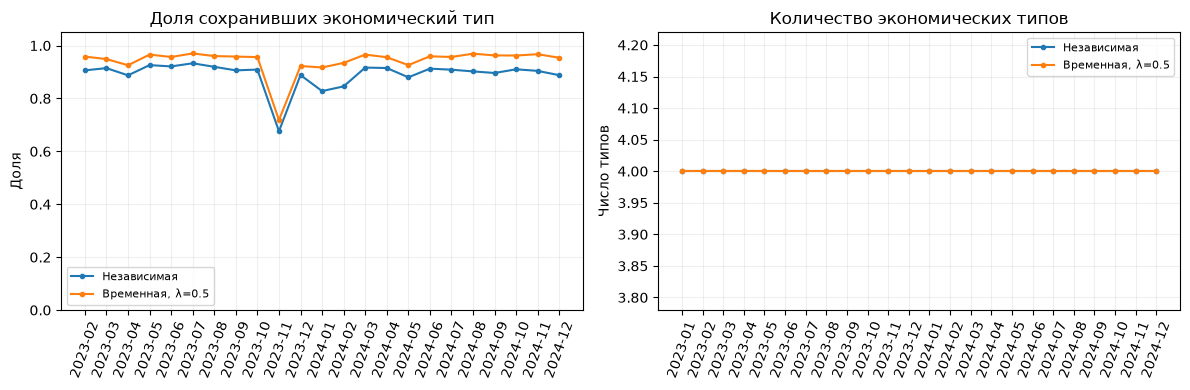

In [5]:
example_lambda = 0.5 if 0.5 in temporal_paths else sorted(temporal_paths)[1]
example_model = temporal_paths[example_lambda]
example_stability = time_metrics(example_model, tcfg['stable_cluster_jaccard'])
association_base = attribute_change_association(independent, features)
association_model = attribute_change_association(example_model, features)
print('Медиана изменения CLR у сменивших и сохранивших тип (по 23 месяцам):')
for name, table in [('Независимая', association_base), (f'λ={example_lambda:g}', association_model)]:
    print(name, '| перешедшие:', round(table.median_clr_change_switch.median(),4),
          '| сохранившие:', round(table.median_clr_change_stay.median(),4),
          '| Spearman:', round(table.spearman_change_vs_switch.median(),3))

fig, axes = plt.subplots(1,2,figsize=(12,4))
axes[0].plot(stability.month_to, stability.stay_share, marker='.', label='Независимая')
axes[0].plot(example_stability.month_to, example_stability.stay_share,
             marker='.', label=f'Временная, λ={example_lambda:g}')
axes[0].set(title='Доля сохранивших экономический тип',ylabel='Доля',ylim=(0,1.05))
axes[1].plot(months,[independent[m].nunique() for m in months],marker='.',label='Независимая')
axes[1].plot(months,[example_model[m].nunique() for m in months],marker='.',label=f'Временная, λ={example_lambda:g}')
axes[1].set(title='Количество экономических типов',ylabel='Число типов')
for ax in axes:
    ax.tick_params(axis='x',rotation=70)
    ax.legend(fontsize=8)
    ax.grid(alpha=.2)
plt.tight_layout(); plt.show()

## 7. Потоки между выбранными периодами

Трёхпериодная диаграмма показывает доли муниципалитетов в типах и существенные переходы между январём 2023, январём 2024 и декабрём 2024. Каждая полоса соединяет сообщества **на основе пересечения муниципалитетов**. Мелкие потоки могут быть скрыты только для читаемости рисунка; в рассчитанных таблицах они сохранены.

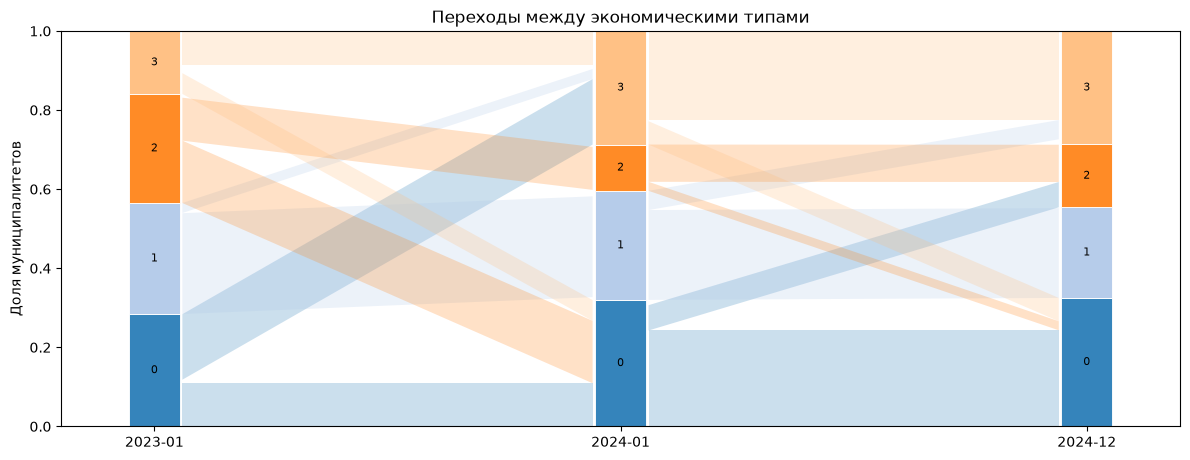

In [6]:
fig, ax = plt.subplots(figsize=(12,4.7))
plot_flow_three_periods(independent, [months[0],months[12],months[-1]], ax=ax,
                        min_flow_share=0.015)
plt.tight_layout(); plt.show()

## 8. Внешний анализ годовых изменений БДМО (`X_delta`)

`X_delta` содержит восемь показателей изменений **между 2023 и 2024 годами**, а не месячные темпы роста. Поэтому сравниваем их с количеством месячных переходов, заканчивающихся в 2024 году, на одних и тех же муниципалитетах. Для каждого показателя рассчитываем число доступных наблюдений и ранговую корреляцию Spearman с частотой переключений; отдельно — корреляцию с абсолютной величиной изменения. Пропуски обрабатываются попарным исключением **без импутации**.

Даты публикации и точное определение разностей (абсолютные или относительные) требуют сверки с реализацией этапа 04. Поэтому анализ ретроспективен: полученные ассоциации **не** доказывают причинную связь и не используются для построения текущих кластеров.

In [7]:
X_delta = pd.read_parquet(ROOT / tcfg['delta_path'])
if not X_delta.index.equals(X_dynamic.index):
    raise ValueError('Порядок идентификаторов X_delta и X_dynamic различается')
delta_assoc = delta_transition_associations(independent, X_delta, year=2024)
print('Размер X_delta:', X_delta.shape, '| сравниваются переходы, заканчивающиеся в 2024 году')
display(delta_assoc.sort_values('spearman_abs_delta_vs_switches',
                               ascending=False).round(3))

Размер X_delta: (2016, 8) | сравниваются переходы, заканчивающиеся в 2024 году


,indicator,n_valid,n_missing,spearman_delta_vs_switches,spearman_abs_delta_vs_switches,transition_pairs,mean_switches
3,profitable_share,2000,16,0.024,0.181,12,1.290
7,lit_street_share,1895,121,-0.029,0.014,12,1.361
5,shop_floor_per_capita,1845,171,-0.043,-0.043,12,1.353
1,employment_per_1000,1844,172,-0.076,-0.056,12,1.244
4,investment_total_per_capita,1834,182,-0.036,-0.072,12,1.244
2,reporting_companies_per_1000,2003,13,0.034,-0.107,12,1.285
0,wage,2001,15,-0.187,-0.188,12,1.292
6,population_density,1990,26,0.073,-0.296,12,1.289


## 9. Анализ результатов и научные выводы

### 9.1. Согласование экономических типов

На 24 месячных срезах представлены **2016 муниципалитетов**, для основного исследования используются разбиения **K-Means** и выбранные экономические графы шага 06. Сопоставление методом Hungarian устранило неоднозначность числовых меток: за весь период использованы **четыре сквозных идентификатора**. Это не означает, что состав каждого типа оставался постоянным.

По установленным порогам пересечений зарегистрированы **21 сигнал разделения** и **20 сигналов объединения**. Они отражают перераспределение муниципалитетов между четырьмя группами, а не возникновение 41 нового экономического сообщества: число типов в каждом месяце остаётся равным четырём. Поскольку сигнал может возникать одновременно с сохранением основного соответствия кластеров, его нельзя трактовать как установленное экономическое событие или причину изменения.

### 9.2. Устойчивость независимых месячных разбиений

Для **23 пар соседних месяцев** средняя доля муниципалитетов с сохранённой меткой составляет **0,891**, медианная — **0,906**; соответственно средняя доля сменивших тип равна **0,109**, медианная — **0,094**. Медианные значения независимых от перестановки меток метрик: **ARI = 0,760** и **NMI = 0,747**. Медианное число устойчивых сообществ при пороге Жаккара 0,5 составляет **4**, минимум — **2**.

Наиболее заметное изменение наблюдается **между октябрём и ноябрём 2023 года**: доля сменивших тип достигает **0,324**. В частности, в таблице потоков обнаружены переходы **0 → 3 (285 муниципалитетов)** и **2 → 0 (182)**. Этот скачок требует отдельной экономической проверки, в том числе на сезонность потребления: сам по себе переход между кластерами не доказывает структурного изменения муниципальной экономики.

### 9.3. Сравнение временной регуляризации

При фиксированном коэффициенте графового согласования $\beta=0{,}15$ выполнено сравнение пяти значений $\lambda$. Основные медианные результаты:

| $\lambda$ | Доля сохранивших тип | ARI соседних месяцев | Модулярность | Стоимость относительно независимого разбиения |
|---:|---:|---:|---:|---:|
| 0 | 0,906 | 0,760 | 0,639 | 1,000 |
| 0,25 | 0,941 | 0,848 | 0,637 | 1,002 |
| 0,50 | 0,957 | 0,887 | 0,631 | 1,007 |
| 1,00 | 0,972 | 0,923 | 0,623 | 1,014 |
| 2,00 | 0,985 | 0,960 | 0,614 | 1,026 |

Регуляризация ожидаемо уменьшает число переходов, но одновременно снижает графовую модулярность и увеличивает стоимость соответствия исходным экономическим признакам. Следовательно, **максимальная временная устойчивость не является достаточным основанием для выбора модели**. При $\lambda=0$ используется уже графово-атрибутивная стоимость с $\beta>0$, поэтому контрольная модель не обязана точно совпадать с исходным K-Means; фактическая медианная ARI с независимыми метками равна **0,994**.

На имеющихся данных **$\lambda=0{,}25$ — осторожный рабочий кандидат**: медианная устойчивость возрастает с 0,906 до 0,941 при небольшом снижении модулярности (0,639 → 0,637) и изменении стоимости на 0,2%. Это **не доказательство оптимальности** параметра: желательно отдельно проверить, какие именно экономически обоснованные переходы исчезают при сглаживании. Значения $\lambda\ge1$ рассматриваются как сценарии более сильного сглаживания, а не предпочтительные варианты лишь по доле сохранения меток.

### 9.4. Соответствие переходов изменениям месячных атрибутов

В независимой кластеризации медиана нормы месячного изменения CLR у сменивших тип составляет **0,2229**, у сохранивших — **0,1599**; медианная корреляция Spearman между величиной изменения и фактом перехода равна **0,172**. Для иллюстративной модели $\lambda=0{,}5$ соответствующие медианы составляют **0,2538** и **0,1625**, а Spearman — **0,154**. Следовательно, переходы в среднем сопровождаются большими изменениями структуры расходов, однако связь умеренная; уменьшение числа переходов при регуляризации не означает автоматического усиления этой зависимости.

### 9.5. Внешняя связь с годовыми изменениями БДМО

Матрица `X_delta` имеет размер **2016 × 8**. Для восьми показателей доступны **1834–2003** муниципалитета; пропуски исключались отдельно по каждому показателю. В 2024 году проанализированы **12 месячных переходов**. Среди наблюдаемых ранговых ассоциаций с числом переходов: для величины изменения **плотности населения** $\rho=-0{,}296$, **доли прибыльных организаций** $\rho=0{,}181$; для подписанного изменения **оплаты труда** $\rho=-0{,}187$. В целом обнаруженные связи различаются по направлению и, как правило, невелики по абсолютной величине.

Результаты не устанавливают причинность. Кроме того, до экономической трактовки знаков необходимо подтвердить точную формулу `X_delta` по этапу 04. Годовая разность 2023–2024 годов не является помесячным изменением; даты публикации годовых показателей здесь не верифицированы.

### 9.6. Методологические ограничения и решение этапа

Временная модель представляет собой **ретроспективную регуляризацию** разбиений K-Means: использует фиксированные месячные прототипы и исходные метки графовых соседей, но **не является совместным переобучением сообществ многослойного графа**. Алгоритм Витерби находит точный минимум сформулированной задачи при этих фиксированных величинах; результат нельзя интерпретировать как прогноз, построенный только на информации, доступной на начало месяца.

**Предварительное решение:** сохранить независимые разбиения как обязательную контрольную модель; принять $\lambda=0{,}25$ как рабочего кандидата для проверки чувствительности в дальнейшем исследовании и оставить $\lambda=0{,}5$ как более сглаженную альтернативу. Окончательное превосходство динамической модели не установлено и подлежит проверке на этапе 09.

## 10. Передача результатов следующему этапу

Будут записаны четыре файла: `temporal_labels.parquet` (исходный индекс, независимая и временная модели), `transitions.parquet` (23 пары месяцев для обеих моделей), `temporal_metrics.parquet` (устойчивость обеих моделей), `temporal_experiment.json` (метод и параметры). Графы, сами CLR-матрицы и все экспериментальные траектории **повторно не сохраняются**.

In [8]:
selected_lambda = tcfg['selection']
if selected_lambda is None:
    print('Сохранение не выполняется: параметр temporal_08.selection пока не выбран.')
else:
    selected_lambda = float(selected_lambda)
    if selected_lambda not in temporal_paths:
        raise ValueError('Выбранная lambda отсутствует в выполненной сетке эксперимента')
    selected_model = temporal_paths[selected_lambda]
    independent_flows = flows.assign(model='independent')
    selected_flows = transitions(selected_model).assign(model='temporal')
    combined_flows = pd.concat([independent_flows,selected_flows],ignore_index=True)
    combined_metrics = pd.concat([
        stability.assign(model='independent'),
        time_metrics(selected_model,tcfg['stable_cluster_jaccard']).assign(model='temporal')
    ],ignore_index=True)
    metadata = {
        'source_stage_07':cfg['output_directory'],
        'source_stage_06':cfg['graph_directory'],
        'source_method':method,
        'months':months,
        'selected_lambda':selected_lambda,
        'graph_beta':tcfg['graph_beta'],
        'emission_scale':model_info['emission_scale'],
        'matching': 'Hungarian max overlap; zero-overlap matches rejected',
        'stable_cluster_jaccard':tcfg['stable_cluster_jaccard'],
        'lambda_grid':tcfg['lambda_values'],
        'interpretation': 'retrospective temporal regularization, not an as-of forecast',
        'delta_role': 'explanatory only',
    }
    save_results(ROOT / tcfg['output_directory'],X_dynamic.index,months,
                 independent,selected_model,combined_flows,combined_metrics,metadata)
    print('Результаты сохранены:',ROOT / tcfg['output_directory'])

Результаты сохранены: /Users/olgakan/vlad/hack/outputs/bdmo_v3/temporal_step08
